# Financial Processes: Lesson 3
## Pricing European options in Binomial Tree Model

# Agenda:

* European options
    * Market
    * Call, Put
* Tree method
    * Concept
    * Example
* Formula for price and delta
* Implementation
* Barrier options
* Coding

# European options

## The market

Two assets:
* Money market (risk free asset, bond): pays a fixed, deterministic interest

* Risky asset (stock): $S_t \sim F_t$, i.e. its present value is known, future is unknown

* Short position is allowed

* No bid-ask spread

## European option

Two parties:
* Option holder (buyer)

* Option writer (seller)

Parameters of the contract:
* Maturity, $T$

* Strike price, $K$

Def (European call/put option): The owner has the right, but not the obligation to buy/sell $1$ share of stock from/to the option writer at $T$ for $K$ (dollars).

Payoff of european call: $ \;\;\; max\lbrace S_T-K, 0\rbrace $

Payoff of european put: $ \;\;\; max\lbrace K - S_T, 0\rbrace $

# The Tree method

## Basic concept of binomial tree model
* Discrete steps, price goes up or down randomly
* Risk-free alternative is government bond

$$ d < 1 + r < u $$

<img src="./img/tree-notation.png" style="margin-left:auto; margin-right:auto; margin-top: 50px; width: 1200px;" />

More than one step is possible

Spot tree: $S_{t,i}$ is the $i^{th}$ value of the time $t$ level of the spot simulation tree. $t = 0, \dots, N,\ i = 0, \dots, t$.

<img src="./img/2-step.png" style="margin-left:auto; margin-right:auto; margin-top: 50px; width: 600px;" />

## Example: pricing European option with one-step tree

<img src="./img/1-step-example.png" style="margin-left:auto; margin-right:auto; margin-top: 150px; width: 1800px;" />

### Arbitrage free price of option

$\textbf{time step}$| $\textbf{draw}$ | $\textbf{bond} \hspace{10px}$ | $\textbf{stock}$ | $\textbf{call option}$ |
--------------:|----:|----:|----:|----:|
$0$|$\emptyset$|$-100$|$-20$|$V_0$
$1$|$U$|$103$|$22$|$1$
$1$|$D$|$103$|$18$|$0$

Q: What is the basic idea?

Can we replicate the cashflows of the option using bonds and stock?

$ S_1(U)-S_1(D) = 4 (V_1(U) - V_1(D)) $

We need to hold $ \Delta_0 = 1/4 $ number of stocks to replicate (Delta-hedging rule)

time step| draw | $\text{bond} \hspace{10px}$  |  $1/4$ stock  | $\text{option} \hspace{10px}$ |
---:|---:|---:|---:|---:|
$0$|$\emptyset$|$\approx 4.37$|$-5$|$V_0\approx 0.63$
$1$|$U$|$-4.5$|$5.5$|$1$
$1$|$D$|$-4.5$|$4.5$|$0$

Q: Where did we use $p$ and $q$?

Q: What if option had another price on the market?

Q: How would you generalize to multi-step?

# Price formula

## One step

* Example table gives an equation system for $V_0$ and $\Delta_0$: amount of stocks to hold for replication

$ V_0 = \frac{1}{1+r}(\tilde{p}\ V_1(U) + \tilde{q}\ V_1(D)) $ and

$ \Delta_0 = \frac{V_1(U) - V_1(D)}{S_1(U) - S_1(D)} $

where

$ \tilde{p} =  \frac{1+r-d}{u-d}$,  $ \tilde{q} = 1 - \tilde{p} $

Q: Where do the formulas depend on the strike $K$?

$\{ \tilde{p}, \tilde{q}\}$ is called the Risk-neutral measure

$ V_0 = \frac{1}{1+r}\tilde{E}(V_1) $

Q: Why do we call it "Risk-neutral measure"?

## Multi-step

  $ V_n = \frac{1}{1+r}\tilde{E}(V_{n+1} \mid \mathcal{F}_n) $
  
  $ \Delta_n = \frac{V_{n+1}(\dots U) - V_{n+1}(\dots D)}{S_{n+1}(\dots U) - S_{n+1}(\dots D)}$
  
  $\text{ for } \ n = N-1,\dots,0$

Therefore:

$ V_0 = \frac{1}{(1+r)^N}\tilde{E}(V_N) $

# Implementation

Two trees:

* Spot tree: $S_{t,i}$ is the $i^{th}$ value of the time $t$ level of the spot simulation tree. $t = 0, \dots, N,\ i = 0, \dots, t$.

<img src="./img/2-step.png" style="margin-left:auto; margin-right:auto; margin-top: 50px; width: 600px;" />

## Evolution of spot tree: code snippet

<img src="./img/spot_tree_code_spaghetti.jpg" style="margin-left:auto; margin-right:auto; margin-top: 150px; width: 1800px;" />

Two trees:
* Spot tree: $S_{t,i}$ is the $i^{th}$ value of the time $t$ level of the spot simulation tree. $t = 0, \dots, N,\ i = 0, \dots, t$.
* **Price tree:** same dimensions, $V_{t,i} = \tilde{E}(V_N \mid S_t = S_{t,i}) $

* Backward solution for price tree (based on multi-step formula)

## Evolution of price tree: code snippets

Leaves:
<img src="./img/price_tree_leaves_European_spaghetti.jpg" style="margin-left:auto; margin-right:1000px; margin-top: 10px; width: 1350px;" />

Backward steps:
<img src="./img/price_tree_code_European_spaghetti.jpg" style="margin-left:auto; margin-right:550px; margin-top: 10px; width: 1800px;" />

## Barrier options

Up and out call: call with a knock-out feature

Barrier: $B>K$

$$V_T = (S_T - K)^+ \mathbb{1}\{S_t < B \ \ \ \forall 0 \leq t \leq T\}$$

Continous barrier: barrier condition is checked on a time interval (as opposed to either terminal condition or discrete barrier)

Q: Main difference from modeling perspective?

# Time to play a bit with the code...

# Summary and discussion

* Market, European Call/Put

* Spot and Price tree

* Replication, hedging

* Formula for price and delta
    * $ V_0 = \tilde{E}(V_N) $, $ V_n = \tilde{E}(V_N \mid \mathcal{F}_n) $
    * To replicate we need to achieve:

      $ \Delta_n(S_{n+1}(\dots U) - S_{n+1}(\dots D)) = V_{n+1}(\dots U) - V_{n+1}(\dots D) $

* In jupyter nb we have seen:
    * Delta is dynamic
    * Balancing the tree
    * Barrier

# Assignment
## Implement calibrator for Tree

* Background: In the Black--Scholes model volatility is a key parameter that determines option price. In a Balanced Binomial Tree (i.e. risk-neutral up step probability $= 0.5$ risk-neutral down step probability $= 0.5$) the same role is played by step size: higher step is like higher volatility, it results in higher option prices. Also, there is a 1-1 correspondence between step size and price if all other parameters are fixed.
* Task: Write a calibrate method which, for a given number of steps parameter, computes the up step size for which a Balanced Binomial Tree model returns the specified price for a given European call. (In practice option prices can be observed in the market, so it makes sense to assume it is given). Demonstrate the calibrate method for various input parameters (same contract with a few different number of steps (dont forget to scale the discount factor to keep interest rates flat); calibrate one step tree for various contracts (different expiries and strike levels, flat interest rate)). Make simple plots to illustrate results.
* Hint: To do it you will need to use a root solver, I recommend using scipy.optimize.minimize.

In [4]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm
from typing import Union, List


def balanced_tree_call_price(
    spot: float,
    strike: float,
    maturity: float,
    rate: float,
    steps: int,
    up: float,
) -> float:
    """Price a European call using a balanced binomial tree."""
    dt = maturity / steps
    R = np.exp(rate * dt)
    discount_factor = 1.0 / R
    down = 2.0 * R - up

    if not (0.0 < down < R < up):
        raise ValueError("Invalid balanced-tree up-step multiplier.")

    price = 0.0

    for j in range(steps + 1):
        terminal_spot = spot * up**j * down**(steps - j)
        payoff = max(terminal_spot - strike, 0.0)
        probability = math.comb(steps, j) / 2**steps
        price += probability * payoff

    return discount_factor**steps * price


def calibrate_tree(
    market_price: float,
    spot: float,
    strike: float,
    maturity: float,
    rate: float,
    steps: int,
) -> float:
    """Find the balanced-tree up multiplier matching a market call price."""
    if steps < 1 or maturity <= 0 or spot <= 0:
        raise ValueError("Steps, maturity, and spot must be positive.")

    R = np.exp(rate * maturity / steps)

    eps = 1e-10 * max(1.0, R)
    lower = R + eps
    upper = 2.0 * R - eps

    def pricing_error(up):
        return (
            balanced_tree_call_price(
                spot, strike, maturity, rate, steps, up
            )
            - market_price
        )

    f_lower = pricing_error(lower)
    f_upper = pricing_error(upper)

    if f_lower * f_upper > 0:
        raise ValueError(
            "Market price is outside the range attainable "
            "by this balanced tree."
        )

    return brentq(pricing_error, lower, upper, xtol=1e-12)

In [5]:

def black_scholes_eur_call(
    r: float,
    T: float,
    S0: float,
    sigma: float,
    K: Union[float, List[float], np.ndarray]
) -> np.ndarray:
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock.
    """
    assert sigma > 0
    assert T > 0

    K = np.array([K]) if isinstance(K, (float, int)) else np.array(K)

    d1_vec = (
        np.log(S0 / K) + (r + 0.5 * sigma**2) * T
    ) / (sigma * T**0.5)

    d2_vec = d1_vec - sigma * T**0.5

    N_d1_vec = norm.cdf(d1_vec)
    N_d2_vec = norm.cdf(d2_vec)

    return S0 * N_d1_vec - K * np.exp(-r * T) * N_d2_vec


# Contract parameters
spot = 100.0
strike = 100.0
maturity = 1.0
rate = 0.05
reference_volatility = 0.20

market_price = black_scholes_call(
    spot, strike, maturity, rate, reference_volatility
)

print(f"Reference market price: {market_price:.6f}")

step_counts = [1, 2, 5, 10, 25, 50, 100]

results = []

for steps in step_counts:
    up = calibrate_tree(
        market_price, spot, strike, maturity, rate, steps
    )
    down = 2 * np.exp(rate * maturity / steps) - up

    model_price = balanced_tree_call_price(
        spot, strike, maturity, rate, steps, up
    )

    results.append((steps, up, down, model_price))

for steps, up, down, model_price in results:
    print(
        f"N={steps:3d} | up={up:.6f} | "
        f"down={down:.6f} | price={model_price:.6f}"
    )


Reference market price: 10.450584
N=  1 | up=1.219728 | down=0.882814 | price=10.450584
N=  2 | up=1.175628 | down=0.875002 | price=10.450584
N=  5 | up=1.096797 | down=0.923304 | price=10.450584
N= 10 | up=1.067825 | down=0.942200 | price=10.450584
N= 25 | up=1.042104 | down=0.961900 | price=10.450584
N= 50 | up=1.029167 | down=0.972834 | price=10.450584
N=100 | up=1.020483 | down=0.980517 | price=10.450584


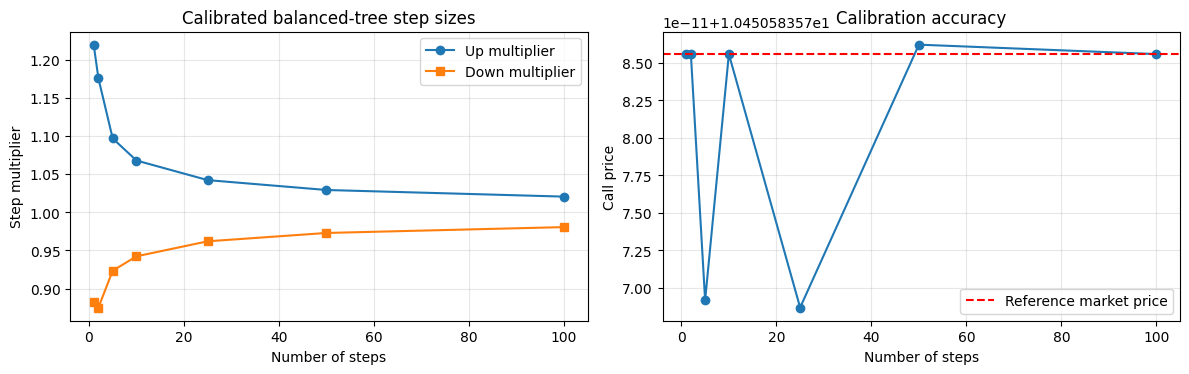

In [6]:
steps_array = np.array([row[0] for row in results])
up_array = np.array([row[1] for row in results])
down_array = np.array([row[2] for row in results])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(steps_array, up_array, "o-", label="Up multiplier")
axes[0].plot(steps_array, down_array, "s-", label="Down multiplier")
axes[0].set_xlabel("Number of steps")
axes[0].set_ylabel("Step multiplier")
axes[0].set_title("Calibrated balanced-tree step sizes")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(steps_array, [row[3] for row in results], "o-")
axes[1].axhline(
    market_price, color="red", linestyle="--",
    label="Reference market price"
)
axes[1].set_xlabel("Number of steps")
axes[1].set_ylabel("Call price")
axes[1].set_title("Calibration accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:

S0 = 100.0
r = 0.05
sigma = 0.20
N = 1

strikes = np.array([80, 90, 100, 110, 120], dtype=float)
maturities = [0.5, 1.0, 2.0]

contract_results = []

for T in maturities:
    market_prices = black_scholes_eur_call(
        r, T, S0, sigma, strikes
    )

    for K, market_price in zip(strikes, market_prices):
        u = calibrate_tree(
            float(market_price), S0, K, T, r, N
        )

        d = 2 * np.exp(r * T / N) - u

        contract_results.append({
            "T": T,
            "K": K,
            "market_price": float(market_price),
            "u": u,
            "d": d,
        })

for row in contract_results:
    print(
        f"T={row['T']:.1f}, K={row['K']:.0f}, "
        f"BS={row['market_price']:.4f}, "
        f"u={row['u']:.6f}, d={row['d']:.6f}"
    )


T=0.5, K=80, BS=22.1746, u=1.254718, d=0.795912
T=0.5, K=90, BS=13.4985, u=1.176805, d=0.873826
T=0.5, K=100, BS=6.8887, u=1.141262, d=0.909368
T=0.5, K=110, BS=2.9065, u=1.159601, d=0.891029
T=0.5, K=120, BS=1.0226, u=1.220970, d=0.829660
T=1.0, K=80, BS=24.5888, u=1.316991, d=0.785552
T=1.0, K=90, BS=16.6994, u=1.251113, d=0.851429
T=1.0, K=100, BS=10.4506, u=1.219728, d=0.882814
T=1.0, K=110, BS=6.0401, u=1.226995, d=0.875547
T=1.0, K=120, BS=3.2475, u=1.268280, d=0.834263
T=2.0, K=80, BS=29.1202, u=1.443657, d=0.766685
T=2.0, K=90, BS=22.0334, u=1.387013, d=0.823329
T=2.0, K=100, BS=16.1268, u=1.356457, d=0.853885
T=2.0, K=110, BS=11.4555, u=1.353205, d=0.857137
T=2.0, K=120, BS=7.9282, u=1.375241, d=0.835101


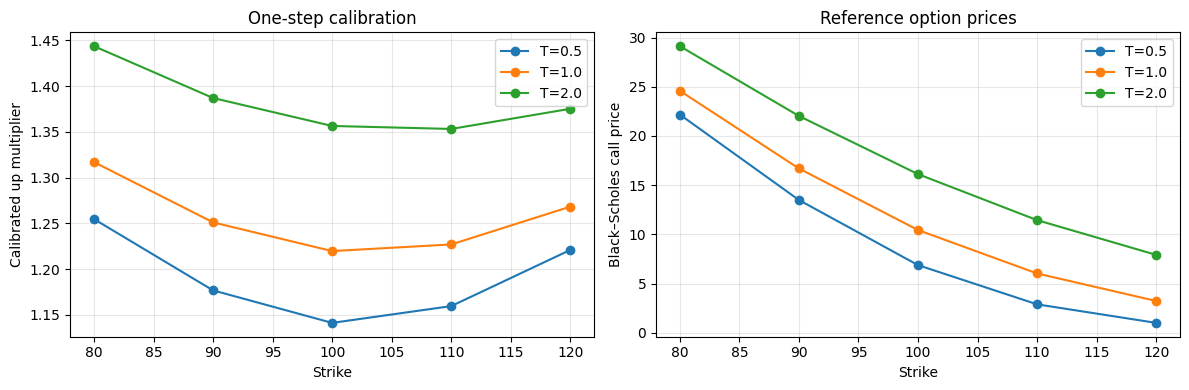

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for T in maturities:
    subset = [row for row in contract_results if row["T"] == T]

    axes[0].plot(
        [row["K"] for row in subset],
        [row["u"] for row in subset],
        "o-", label=f"T={T}"
    )

    axes[1].plot(
        [row["K"] for row in subset],
        [row["market_price"] for row in subset],
        "o-", label=f"T={T}"
    )

axes[0].set_xlabel("Strike")
axes[0].set_ylabel("Calibrated up multiplier")
axes[0].set_title("One-step calibration")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_xlabel("Strike")
axes[1].set_ylabel("Black–Scholes call price")
axes[1].set_title("Reference option prices")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Literature
* Steven Shreve: Stochastic Calculus and Finance I.

# Thanks

<img src="./img/money_tree.jpg" style="margin-left:auto; margin-right:auto; margin-top: 100px; width: 700px;" />